# 05 · Hyperliquid: verifica di robustezza su un mercato crypto L4 (E4)

**Domanda di ricerca.** Quanto cambia la valutazione di una strategia di market making passivo quando le esecuzioni stimate con regole L2 vengono confrontate con un replay order-level che considera la posizione nella coda? Qui la stessa domanda è posta su un secondo mercato, come **verifica di robustezza**.

**Hyperliquid** è un exchange decentralizzato di contratti perpetui. Il dataset di Albers et al. (2026) registra ogni modifica del book con il singolo ordine e l'utente che lo ha inserito (dato **L4**), insieme all'elenco pubblico degli scambi.

**Dati:** BTC-PERP, sei ore (1-3 dicembre 2025, ore 08 e 14 UTC). Calibrazione 1/12 ore 08, validazione 1/12 ore 14, test **4 ore**. Quota di 0,01 BTC per lato.

**Costi.** Le tariffe usate (Nasdaq: rebate di 0,20 cent/azione al maker, 0,30 cent/azione al taker; Hyperliquid: 1,5 bps maker e 4,5 bps taker al livello base, −0,3 e 2,4 bps al livello alto) sono **ipotesi sperimentali indicative**, da verificare sulle tabelle ufficiali del periodo analizzato.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti esplorative
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

R.show_box("Perché questo risultato è secondario", [
    "I book diff non contengono timestamp: durata degli ordini e latenza sono misurate in numero di eventi (circa 700 al secondo).",
    "Fill e cancellazioni sono distinti associando gli scambi pubblici all'`oid` dell'ordine passivo (maker).",
    "Se un ordine subisce più riduzioni, senza orari non si può ricostruire con certezza l'ordine temporale: la classificazione può attribuire alle prime riduzioni un volume eseguito osservato più tardi.",
    "Per questi motivi Hyperliquid è un test di robustezza e non sostituisce ITCH come evidenza principale.",
])

> **Perché questo risultato è secondario**
>
> - I book diff non contengono timestamp: durata degli ordini e latenza sono misurate in numero di eventi (circa 700 al secondo).
> - Fill e cancellazioni sono distinti associando gli scambi pubblici all'`oid` dell'ordine passivo (maker).
> - Se un ordine subisce più riduzioni, senza orari non si può ricostruire con certezza l'ordine temporale: la classificazione può attribuire alle prime riduzioni un volume eseguito osservato più tardi.
> - Per questi motivi Hyperliquid è un test di robustezza e non sostituisce ITCH come evidenza principale.

In [2]:
def bias_figure(name, stats, unit, filename):
    """P&L per regola e rapporto tra esecuzioni L2 ed esecuzioni con la coda."""
    bias = R.fill_bias(test, name).median()
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
    R.bar_by_model(axes[0], stats, "P&L lordo medio (IC 95% per sessione)", unit)
    linthresh = 10 ** np.ceil(np.log10(max(1.0, abs(stats.loc["coda FIFO", "media"]))))
    axes[0].set_yscale("symlog", linthresh=linthresh, linscale=0.5)
    axes[1].bar([R.LABELS[m] for m in bias.index], bias, color=[R.COLORS[m] for m in bias.index], width=0.6)
    for k, v in enumerate(bias):
        axes[1].text(k, v * 1.08, f"{it(v, 1)}×", ha="center", va="bottom", color=R.INK)
    axes[1].axhline(1, color=R.INK, linewidth=0.8)
    axes[1].set(yscale="log", title="Esecuzioni L2 / esecuzioni con la coda (mediana)", ylabel="Rapporto", ylim=(0.5, bias.max() * 3))
    axes[1].grid(axis="x", visible=False)
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches="tight")
    plt.show()
    return bias


def same_session_table(name, session, symbol, fee, net):
    """Tutte le metriche di una singola sessione, stessi parametri, quattro modelli."""
    from market_making_tesi.evaluation import order_fill_rate
    rows = test[(test.dataset == name) & (test.session == session) & (test.symbol == symbol)].set_index("model")
    rows = rows.loc[[m for m in R.MODEL_ORDER if m in rows.index]]
    queue_fills = rows.loc["queue", "maker_fills"]
    table = pd.DataFrame({
        "esecuzioni maker": rows.maker_fills.map(lambda v: it(v)),
        "rapporto con la coda": (rows.maker_fills / queue_fills).map(lambda v: f"{it(v, 1)}×"),
        "quote eseguite": order_fill_rate(rows).map(lambda v: pct(v, 1)),
        "turnover (USD)": rows.turnover.map(lambda v: it(v)),
        "P&L lordo": rows.final_equity.map(lambda v: it(v, 2)),
        "commissioni": (-rows[fee]).map(lambda v: it(v, 2)),
        "P&L netto": rows[net].map(lambda v: it(v, 2)),
        "edge maker": rows.maker_edge.map(lambda v: it(v, 2)),
        "costo liquidazioni": rows.liquidation_cost.map(lambda v: it(v, 2)),
        "P&L di inventario": rows.inventory_pnl.map(lambda v: it(v, 2)),
        "markout": rows.adverse_selection.map(lambda v: it(v, 2)),
        "inventario massimo": rows.max_abs_inventory_seen.map(lambda v: it(v, 2)),
        "rifiuti post-only": rows.post_only_rejects.map(lambda v: it(v)),
    })
    table.index = [R.LABELS[m] for m in table.index]
    return table.T

stats = R.model_table_grouped(test, "hyperliquid", "final_equity")
queue = test[(test.dataset == "hyperliquid") & (test.model == "queue")]
ingest = pd.DataFrame(R.load_json(ROOT, "ingest/hyperliquid")["sessions"]).set_index("session")
R.show_box("In breve", [
    f"Tra il {pct((ingest.fill_volume / ingest.trade_volume).min(), 0)} e il {pct((ingest.fill_volume / ingest.trade_volume).max(), 0)} del volume scambiato viene ricondotto a ordini del book.",
    f"Con la coda reale la strategia ha un P&L netto medio di {it(queue.net_tier0.mean(), 2)} USD per ora, negativo in {it((queue.net_tier0 < 0).sum())} ore su {len(queue)}.",
    "Lo spread di BTC è quasi sempre di un dollaro: lo spread incassato è minimo rispetto alle commissioni.",
])

> **In breve**
>
> - Tra il 97% e il 99% del volume scambiato viene ricondotto a ordini del book.
> - Con la coda reale la strategia ha un P&L netto medio di -47,28 USD per ora, negativo in 4 ore su 4.
> - Lo spread di BTC è quasi sempre di un dollaro: lo spread incassato è minimo rispetto alle commissioni.

## 1. Dai dati grezzi agli eventi

Per ogni ora: modifiche del book di BTC, esecuzioni e cancellazioni ricavate e quota del volume scambiato attribuita. Le modifiche su ordini inseriti prima dell'inizio dell'ora non si possono collegare a nulla e vengono scartate.

In [3]:
quality = R.load(ROOT, "quality").query("dataset == 'hyperliquid'").set_index("session")
display(pd.DataFrame({
    "modifiche del book BTC": ingest.diffs.map(lambda v: it(v)),
    "esecuzioni": ingest.fill_events.map(lambda v: it(v)),
    "cancellazioni": ingest.cancel_events.map(lambda v: it(v)),
    "volume scambiato attribuito": (ingest.fill_volume / ingest.trade_volume).map(lambda v: pct(v, 1)),
    "modifiche su ordini precedenti": ingest.unknown_order_diffs.map(lambda v: it(v)),
    "book incrociato": quality.crossed_share.map(lambda v: pct(v, 2)),
}))

,modifiche del book BTC,esecuzioni,cancellazioni,volume scambiato attribuito,modifiche su ordini precedenti,book incrociato
session,,,,,,
20251201T08,2.420.117,17.444,1.186.941,"98,3%",14.751,"0,00%"
20251201T14,4.031.702,36.484,1.967.011,"99,4%",30.667,"0,00%"
20251202T08,2.470.744,23.698,1.205.535,"96,5%",17.800,"0,00%"
20251202T14,4.808.729,49.791,2.339.637,"97,2%",41.821,"0,00%"
20251203T08,2.622.419,19.658,1.285.047,"97,8%",16.569,"0,00%"
20251203T14,5.536.288,64.993,2.687.374,"96,8%",50.401,"0,00%"


## 2. Scelta dei parametri (validazione)

P&L netto medio (USD, commissioni di livello base) sull'**unica ora** di validazione: la scelta può adattarsi al caso, la griglia completa serve da analisi di sensibilità.

In [4]:
display(R.validation_grid(validation, "hyperliquid", "net_tier0").style.format("{:.2f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"**Parametri scelti:** {R.params_text('hyperliquid', selected['hyperliquid']['params'])}."))

**Parametri scelti:** volatilità su una finestra di 5.000 eventi; si opera solo sotto il 50° percentile della volatilità di calibrazione; ogni quota resta nel book al massimo 5.000 eventi.

## 3. P&L lordo, commissioni e P&L netto

Per ogni modello, valori medi per ora di test (USD). Gli scenari di commissione sono due: livello base (tier 0) e livello alto.

In [5]:
hl = test[test.dataset == "hyperliquid"].groupby("model")[["final_equity", "fees_tier0", "fees_tier_alto", "net_tier0", "net_tier_alto", "turnover", "maker_fills"]].mean()
hl = hl.loc[[m for m in R.MODEL_ORDER if m in hl.index]]
display(pd.DataFrame({
    "P&L lordo": hl.final_equity.map(lambda v: it(v, 2)),
    "commissioni tier 0": hl.fees_tier0.map(lambda v: it(v, 2)),
    "commissioni tier alto": hl.fees_tier_alto.map(lambda v: it(v, 2)),
    "P&L netto tier 0": hl.net_tier0.map(lambda v: it(v, 2)),
    "P&L netto tier alto": hl.net_tier_alto.map(lambda v: it(v, 2)),
    "turnover (USD)": hl.turnover.map(lambda v: it(v)),
    "esecuzioni maker": hl.maker_fills.map(lambda v: it(v)),
}).rename(index=R.LABELS))
display(Markdown(
    f"**Come leggerlo.** `touch` ha un P&L lordo di {it(hl.loc['touch', 'final_equity'], 2)} USD per ora ma, contando "
    f"{it(hl.loc['touch', 'maker_fills'])} esecuzioni e un turnover di {it(hl.loc['touch', 'turnover'])} USD, al netto delle "
    f"commissioni base perde {it(-hl.loc['touch', 'net_tier0'], 2)} USD: il numero irrealistico di esecuzioni rende "
    "il risultato privo di significato anche come limite superiore netto. Gli importi in USD per ora non sono "
    "confrontabili con le unità normalizzate di FI-2010."))

,P&L lordo,commissioni tier 0,commissioni tier alto,P&L netto tier 0,P&L netto tier alto,turnover (USD),esecuzioni maker
model,,,,,,,
touch,"3.814,26","97.692,69","-19.459,29","-93.878,43","23.273,55",650.804.300,723.358
price-through,"-32,58","190,31","62,98","-222,89","-95,56",656.341,389
cross,"-28,60","164,18","54,66","-192,78","-83,25",564.295,332
coda FIFO,"-3,25","44,04","12,84","-47,28","-16,08",162.407,308


**Come leggerlo.** `touch` ha un P&L lordo di 3.814,26 USD per ora ma, contando 723.358 esecuzioni e un turnover di 650.804.300 USD, al netto delle commissioni base perde 93.878,43 USD: il numero irrealistico di esecuzioni rende il risultato privo di significato anche come limite superiore netto. Gli importi in USD per ora non sono confrontabili con le unità normalizzate di FI-2010.

## 4. Coda reale contro regole L2

,ore indipendenti,titolo-sessioni,P&L netto medio (IC 95% per sessione),IC 95% per riga (confronto),titolo-sessioni positive,quote eseguite (fill rate),turnover medio
touch,4,4,"-93.878,43 (-120.920,76; -66.836,10)","(-120.920,76; -66.836,10)",0%,"100,0%",650.804.300
price-through,4,4,"-222,89 (-246,82; -198,96)","(-246,82; -198,96)",0%,"51,8%",656.341
cross,4,4,"-192,78 (-229,34; -160,61)","(-229,34; -160,61)",0%,"44,7%",564.295
coda FIFO,4,4,"-47,28 (-56,71; -34,16)","(-56,71; -34,16)",0%,"21,3%",162.407


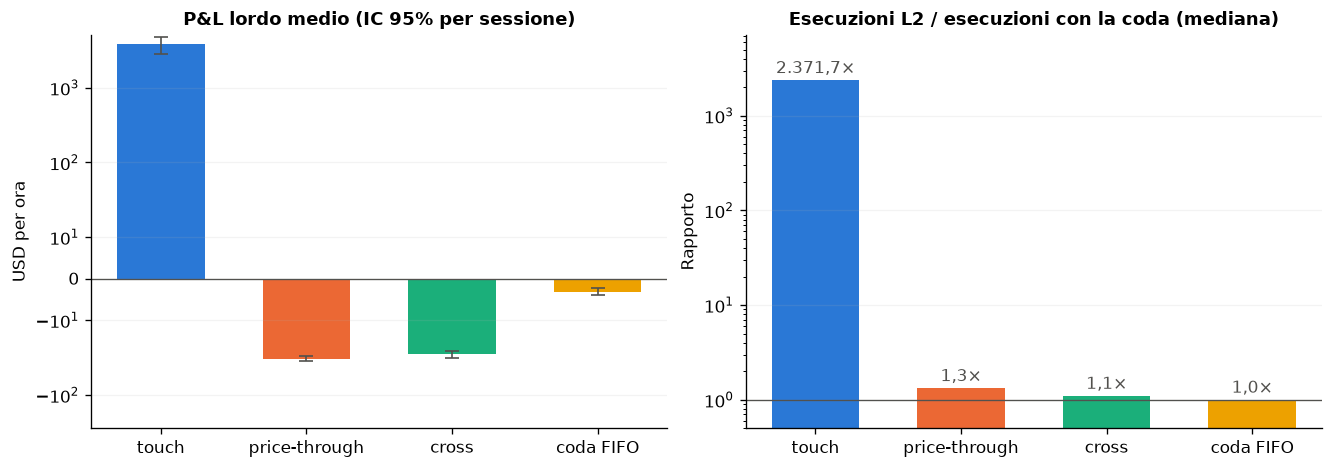

*Figura.* P&L lordo medio per modello (sinistra) e rapporto tra le esecuzioni di ogni regola e quelle della coda (destra). La distorsione di `touch` è ancora maggiore che su ITCH: 2.372 volte le esecuzioni della coda, perché su BTC il prezzo resta fermo per moltissimi eventi consecutivi. *Limite:* quattro ore di test e la classificazione approssimata delle esecuzioni rendono il risultato indicativo.

,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo,commissioni e rebate,= P&L netto
touch,"3.836,85","-5,46","-17,13","3.814,26","-97.692,69","-93.878,43"
price-through,"-0,08","-7,65","-24,84","-32,58","-190,31","-222,89"
cross,"-7,99","-5,54","-15,06","-28,60","-164,18","-192,78"
coda FIFO,"0,59","-1,27","-2,57","-3,25","-44,04","-47,28"


**Come leggerlo.** Con la coda reale lo spread incassato (0,59 USD per ora) è trascurabile rispetto alle commissioni (44,04 USD), che spiegano quasi tutta la perdita.

In [6]:
display(R.overview_table(test, "hyperliquid", "net_tier0", 2))
bias = bias_figure("hyperliquid", stats, "USD per ora", "hyperliquid_test.png")
R.caption("P&L lordo medio per modello (sinistra) e rapporto tra le esecuzioni di ogni regola e quelle della coda (destra).",
          f"La distorsione di `touch` è ancora maggiore che su ITCH: {it(bias['touch'])} volte le esecuzioni della coda, "
          "perché su BTC il prezzo resta fermo per moltissimi eventi consecutivi.",
          "quattro ore di test e la classificazione approssimata delle esecuzioni rendono il risultato indicativo.")
dec = R.decomposition(test, "hyperliquid", "fees_tier0")
display(R.decomposition_table(dec, 2))
d = dec.loc["coda FIFO"]
display(Markdown(
    f"**Come leggerlo.** Con la coda reale lo spread incassato ({it(d['maker_edge'], 2)} USD per ora) è trascurabile "
    f"rispetto alle commissioni ({it(-d['fees'], 2)} USD), che spiegano quasi tutta la perdita."))

## 5. Filtro di volatilità e varianti esplorative

In [7]:
display(Markdown("**Con filtro e sempre attiva** (P&L netto per ora, USD, commissioni base)"))
display(R.filter_table(R.filter_effect(test, ablation, "hyperliquid", "net_tier0"), 2))
display(Markdown("**Varianti esplorative** (P&L netto per ora, USD)"))
display(R.variants_table(R.variant_effect(test, variants, "hyperliquid", "net_tier0", fee_column="fees_tier0"), 2))
display(Markdown(
    "**Come leggerlo.** Il filtro di volatilità e quello di imbalance riducono la perdita soprattutto perché la "
    "strategia **opera meno** e paga meno commissioni; il P&L netto resta negativo."))

**Con filtro e sempre attiva** (P&L netto per ora, USD, commissioni base)

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera
modello,,,,,
touch,"-93.878,43","-152.200,57","58.322,14 (21.229,30; 95.414,99)",100%,32%
price-through,"-222,89","-527,89","305,00 (75,00; 535,01)",100%,32%
cross,"-192,78","-525,62","332,84 (87,90; 577,78)",100%,32%
coda FIFO,"-47,28","-122,34","75,05 (22,26; 127,84)",100%,32%


**Varianti esplorative** (P&L netto per ora, USD)

,P&L netto medio (IC 95%),sessioni positive,differenza vs base (IC 95%),liquidazioni a mercato per sessione
variante,,,,
base,"-47,28 (-56,71; -34,16)",0%,—,118
inventory skew,"-39,33 (-44,33; -31,14)",0%,"7,95 (1,72; 14,18)",92
filtro di imbalance,"-6,40 (-9,87; -3,92)",0%,"40,88 (28,79; 49,76)",14
skew + imbalance,"-5,64 (-8,43; -3,58)",0%,"41,65 (29,50; 50,35)",11


**Come leggerlo.** Il filtro di volatilità e quello di imbalance riducono la perdita soprattutto perché la strategia **opera meno** e paga meno commissioni; il P&L netto resta negativo.